## Automobile Insurance Customer Analytics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid",palette="deep")

In [2]:
df = pd.read_csv("customer-data.csv")
df.head()

,id,age,gender,race,driving_experience,education,income,credit_score,vehicle_ownership,vehicle_year,married,children,postal_code,annual_mileage,vehicle_type,speeding_violations,DUIs,past_accidents,outcome
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,True,after 2015,False,True,10238,12000.0,sedan,0,0,0,False
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,False,before 2015,False,False,10238,16000.0,sedan,0,0,0,True
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,True,before 2015,False,False,10238,11000.0,sedan,0,0,0,False
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,True,before 2015,False,True,32765,11000.0,sedan,0,0,0,False
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,True,before 2015,False,False,32765,12000.0,sedan,2,0,1,True


In [3]:
df.describe()

,id,credit_score,postal_code,annual_mileage,speeding_violations,DUIs,past_accidents
count,10000.000000,9018.000000,10000.000000,9043.000000,10000.000000,10000.00000,10000.000000
mean,500521.906800,0.515813,19864.548400,11697.003207,1.482900,0.23920,1.056300
std,290030.768758,0.137688,18915.613855,2818.434528,2.241966,0.55499,1.652454
min,101.000000,0.053358,10238.000000,2000.000000,0.000000,0.00000,0.000000
25%,249638.500000,0.417191,10238.000000,10000.000000,0.000000,0.00000,0.000000
50%,501777.000000,0.525033,10238.000000,12000.000000,0.000000,0.00000,0.000000
75%,753974.500000,0.618312,32765.000000,14000.000000,2.000000,0.00000,2.000000
max,999976.000000,0.960819,92101.000000,22000.000000,22.000000,6.00000,15.000000


In [4]:
df.dtypes

id                       int64
age                     object
gender                  object
race                    object
driving_experience      object
education               object
income                  object
credit_score           float64
vehicle_ownership         bool
vehicle_year            object
married                   bool
children                  bool
postal_code              int64
annual_mileage         float64
vehicle_type            object
speeding_violations      int64
DUIs                     int64
past_accidents           int64
outcome                   bool
dtype: object

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
 df.isna().sum()

id                       0
age                      0
gender                   0
race                     0
driving_experience       0
education                0
income                   0
credit_score           982
vehicle_ownership        0
vehicle_year             0
married                  0
children                 0
postal_code              0
annual_mileage         957
vehicle_type             0
speeding_violations      0
DUIs                     0
past_accidents           0
outcome                  0
dtype: int64

In [7]:
# Outcome rates by missingness
for col in ["credit_score","annual_mileage"]:
    df[f"{col}_missing"] = df[col].isna()
    print(f"\nOutcome rate by missingness in {col}:")
    print(df.groupby(f"{col}_missing",observed=True)["outcome"].mean())


Outcome rate by missingness in credit_score:
credit_score_missing
False    0.313706
True     0.309572
Name: outcome, dtype: float64

Outcome rate by missingness in annual_mileage:
annual_mileage_missing
False    0.310738
True     0.337513
Name: outcome, dtype: float64


In [8]:
# Filling in missing values
df["credit_score"] = df["credit_score"].fillna(
    df.groupby("income")["credit_score"].transform("mean"))

In [9]:
mean_mileage = df["annual_mileage"].mean()
df.fillna({"annual_mileage":mean_mileage},inplace=True)

### Univariate Analysis

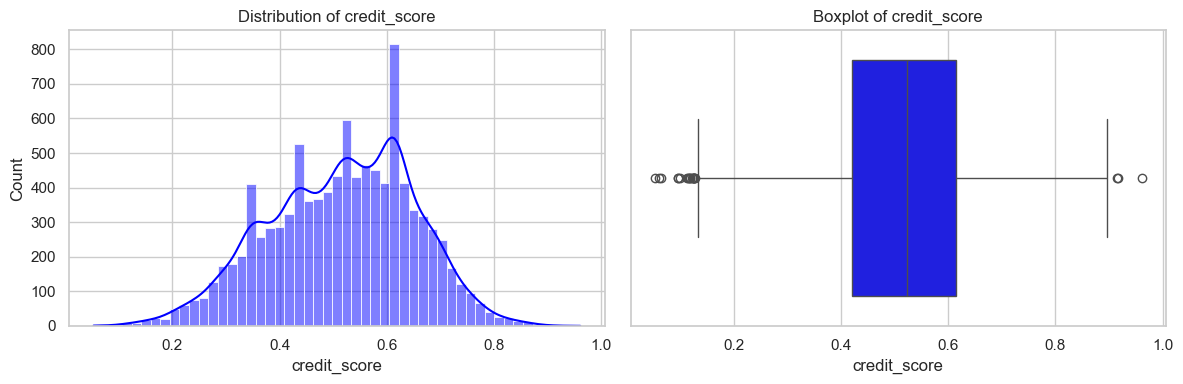

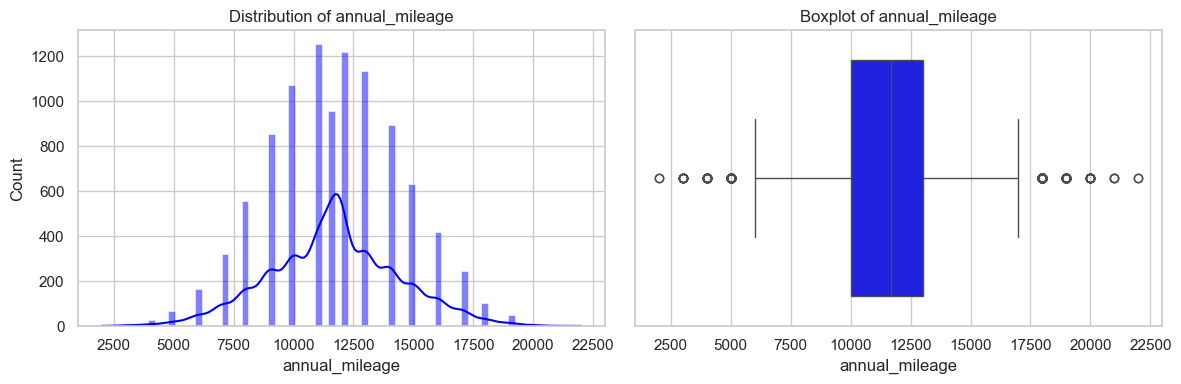

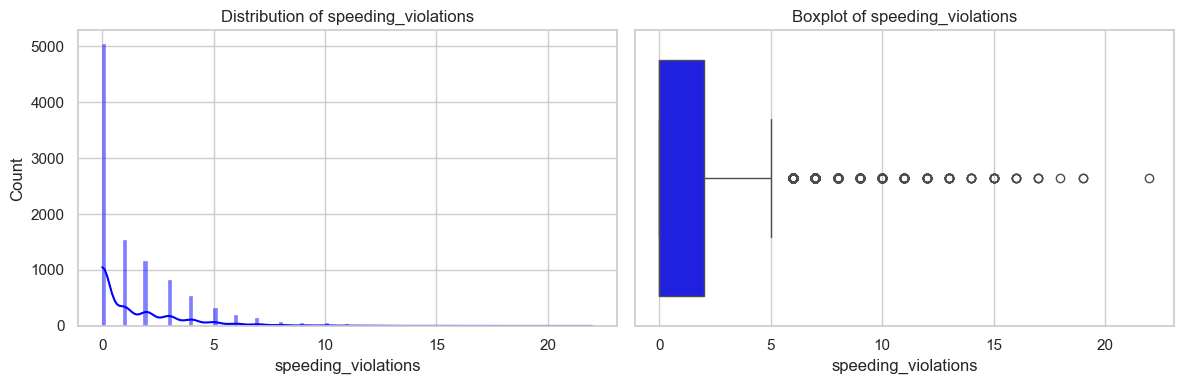

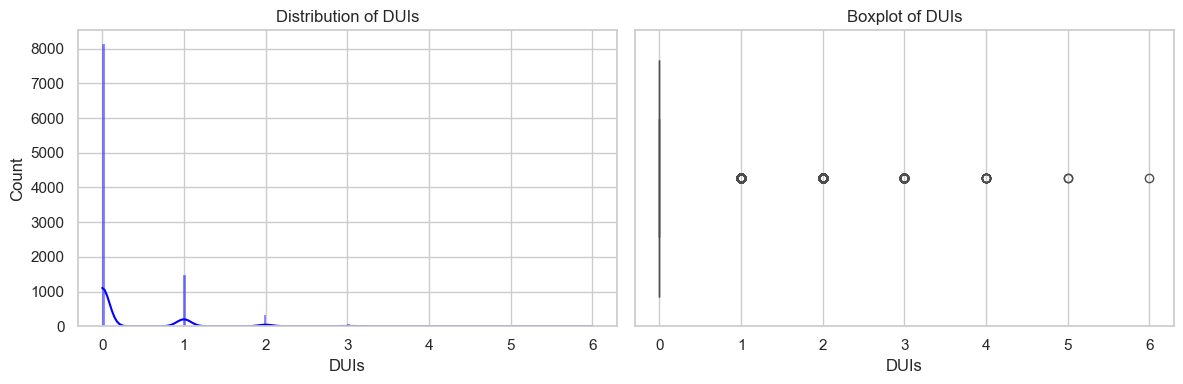

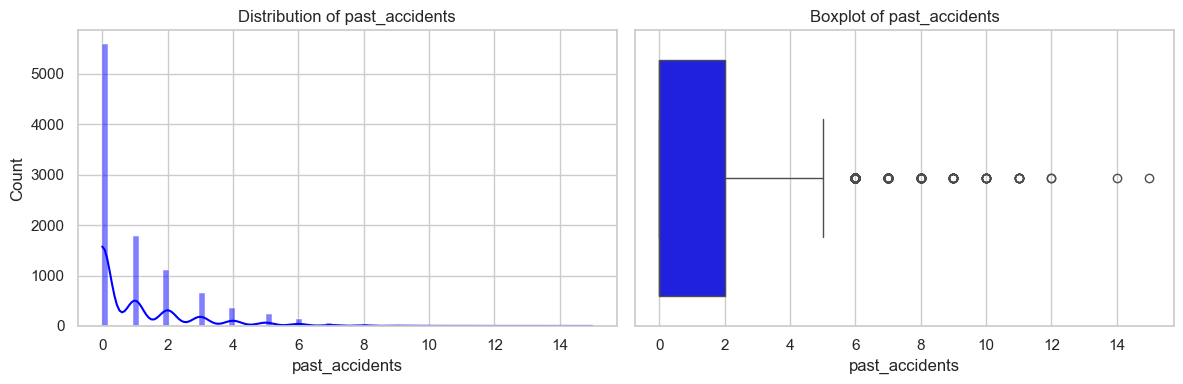

In [10]:
numeric_cols = ["credit_score","annual_mileage","speeding_violations","DUIs","past_accidents"]
for col in numeric_cols:
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    sns.histplot(data=df,x=col,kde=True,ax=axes[0],color="blue")
    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(data=df,x=col,ax=axes[1],color="blue")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

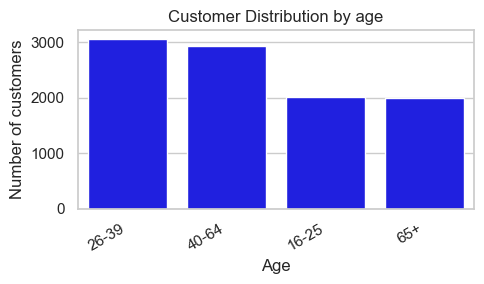

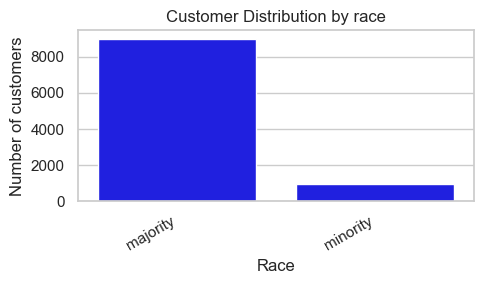

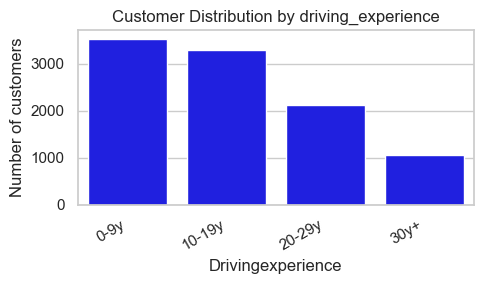

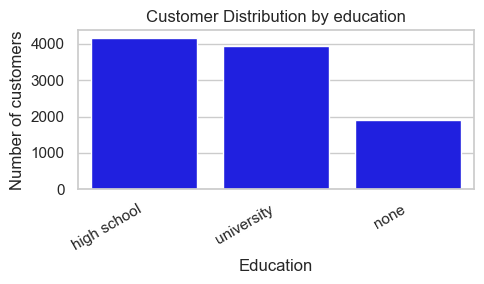

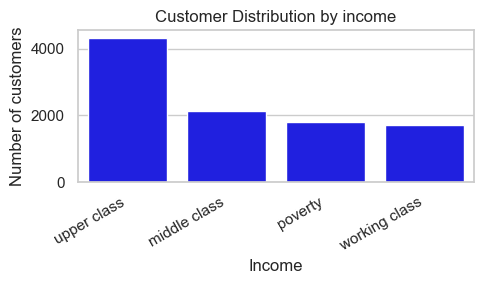

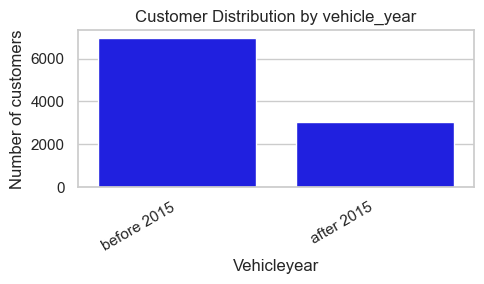

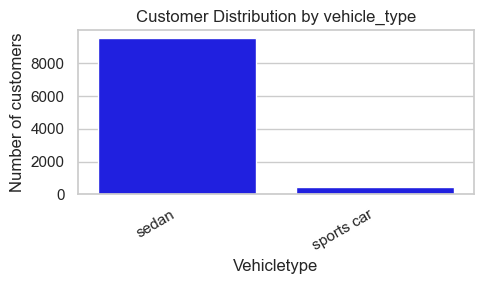

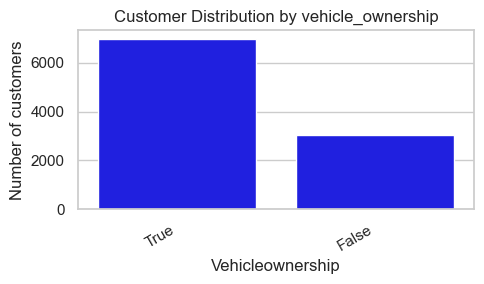

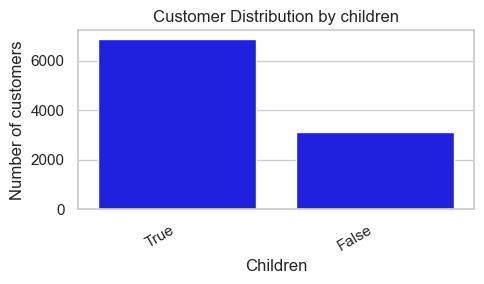

In [11]:
categorical_cols = ["age","race","driving_experience","education",
 "income","vehicle_year","vehicle_type","vehicle_ownership","children"]

for col in categorical_cols:
    plt.figure(figsize=(5,3))
    order = df[col].value_counts().index
    sns.countplot(data=df,x=col,order=order,color="blue")

    plt.title(f"Customer Distribution by {col}")
    plt.xlabel(col.replace("_","").title())
    plt.ylabel("Number of customers")
    plt.xticks(rotation=30,ha="right")
    plt.tight_layout()
    plt.show()

### Outlier detection and investigation

In [12]:
outlier_results = []
for col in numeric_cols:
    series = df[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    mask = (df[col] < lower) | (df[col] > upper)
    outlier_results.append({
        "Column":col,
        "Lower_Bound":lower,
        "Upper_Bound":upper,
        "Outlier_count":int(mask.sum()),"outlier_percentage":round(mask.mean()*100,2)
    })
    print(f"\n{col}:")
    print(df.loc[mask,["id",col,"outcome"]].head(10))
    outlier_summary = pd.DataFrame(outlier_results) 
    display(outlier_summary)


credit_score:
          id  credit_score  outcome
294   232470      0.126453     True
2134   17273      0.123978    False
2152  255200      0.053358     True
2955   88282      0.127418    False
3037  729287      0.116264    False
3156  766245      0.123795     True
3977  696638      0.121826     True
4438  983202      0.125876     True
4552  224416      0.915883    False
4955  237974      0.064810    False


,Column,Lower_Bound,Upper_Bound,Outlier_count,outlier_percentage
0,credit_score,0.132513,0.902616,21,0.21



annual_mileage:
         id  annual_mileage  outcome
19   240658         18000.0     True
68   623367          5000.0    False
287  175635          5000.0     True
298  532459         18000.0    False
300   88882          5000.0    False
477  136957          5000.0     True
572  574525         19000.0     True
726   33697         18000.0     True
739  353690         18000.0    False
849  162234         18000.0    False


,Column,Lower_Bound,Upper_Bound,Outlier_count,outlier_percentage
0,credit_score,0.132513,0.902616,21,0.21
1,annual_mileage,5500.000000,17500.000000,273,2.73



speeding_violations:
        id  speeding_violations  outcome
6   930134                    7    False
10  275820                    6    False
16  517747                   10    False
24  633896                   13    False
38  429947                    6    False
42   10843                   10    False
46  173782                    7    False
52  370044                    9    False
90  680717                    6    False
97  198273                    8    False


,Column,Lower_Bound,Upper_Bound,Outlier_count,outlier_percentage
0,credit_score,0.132513,0.902616,21,0.21
1,annual_mileage,5500.000000,17500.000000,273,2.73
2,speeding_violations,-3.000000,5.000000,588,5.88



DUIs:
        id  DUIs  outcome
10  275820     2    False
12  429728     1    False
14  980181     2    False
16  517747     2    False
22  892754     1    False
24  633896     2    False
26   98515     1    False
31  951465     1    False
40   80496     1    False
42   10843     2    False


,Column,Lower_Bound,Upper_Bound,Outlier_count,outlier_percentage
0,credit_score,0.132513,0.902616,21,0.21
1,annual_mileage,5500.000000,17500.000000,273,2.73
2,speeding_violations,-3.000000,5.000000,588,5.88
3,DUIs,0.000000,0.000000,1882,18.82



past_accidents:
         id  past_accidents  outcome
10   275820               7    False
70   547974               7     True
72   422816               7    False
87   828462               6    False
91   978021               6    False
122  602998               7    False
151  288712               7    False
180  784462               6    False
183  577965               6    False
206  884967               8    False


,Column,Lower_Bound,Upper_Bound,Outlier_count,outlier_percentage
0,credit_score,0.132513,0.902616,21,0.21
1,annual_mileage,5500.000000,17500.000000,273,2.73
2,speeding_violations,-3.000000,5.000000,588,5.88
3,DUIs,0.000000,0.000000,1882,18.82
4,past_accidents,-3.000000,5.000000,285,2.85


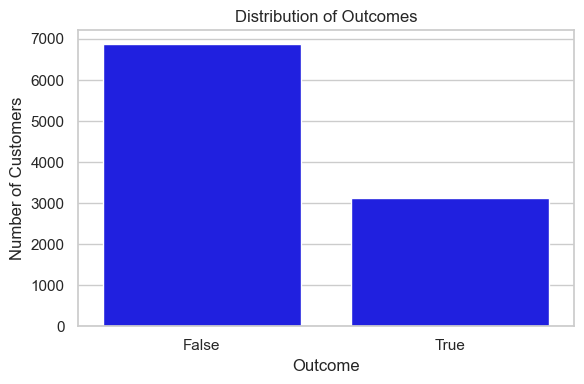

In [13]:
# Outcome distribution
outcome_counts = df["outcome"].value_counts().sort_index()
plt.figure(figsize=(6,4))

sns.barplot(x=outcome_counts.index.astype(str),y=outcome_counts.values,color="blue")
plt.title("Distribution of Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Bivariate Analysis

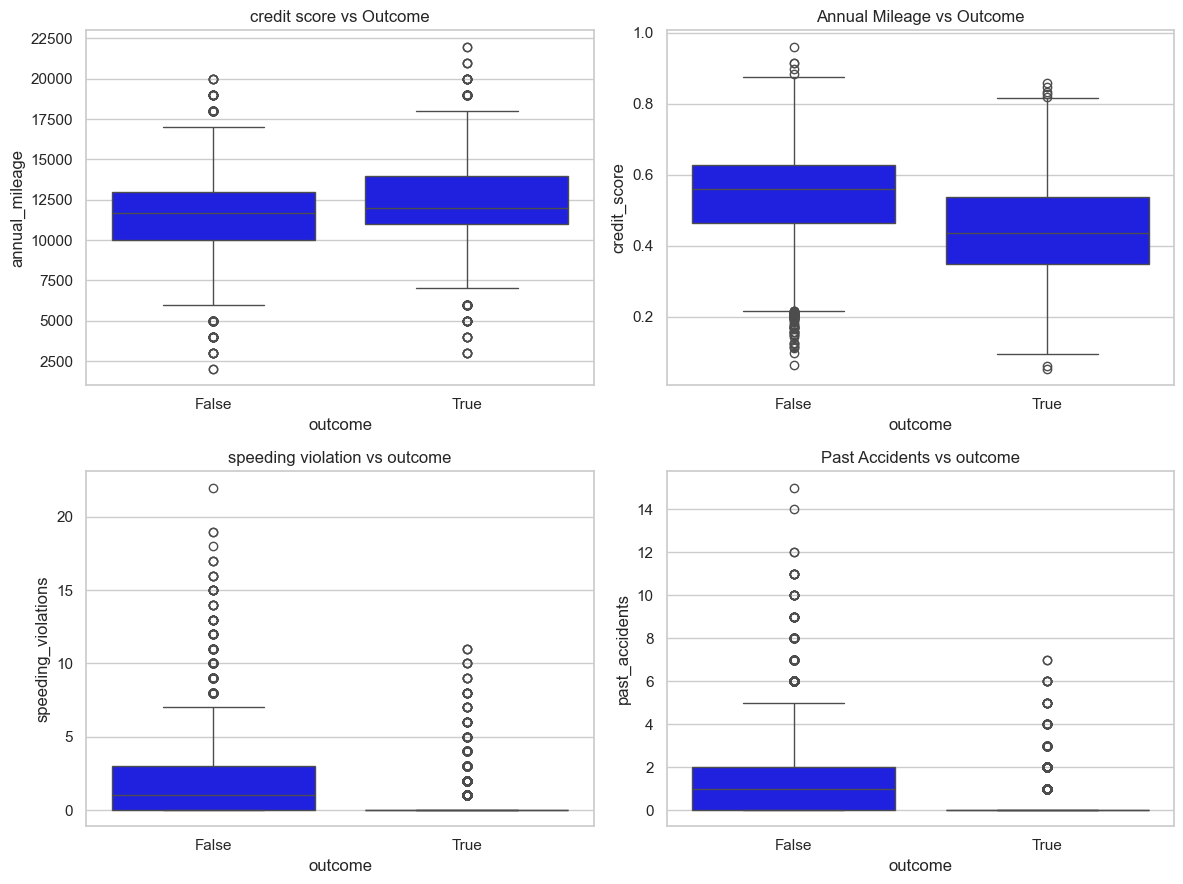

In [14]:
fig,axes = plt.subplots(2,2,figsize=(12,9))
sns.boxplot(data=df,x="outcome",y="credit_score",ax=axes[0,1],color="blue")
axes[0,0].set_title("credit score vs Outcome")

sns.boxplot(data=df,x="outcome",y="annual_mileage",ax=axes[0,0],color="blue")
axes[0,1].set_title("Annual Mileage vs Outcome")

sns.boxplot(data=df,x="outcome",y="speeding_violations",ax=axes[1,0],color="blue")
axes[1,0].set_title("speeding violation vs outcome")

sns.boxplot(data=df,x="outcome",y="past_accidents",ax=axes[1,1],color="blue")
axes[1,1].set_title("Past Accidents vs outcome")
plt.tight_layout()
plt.show()

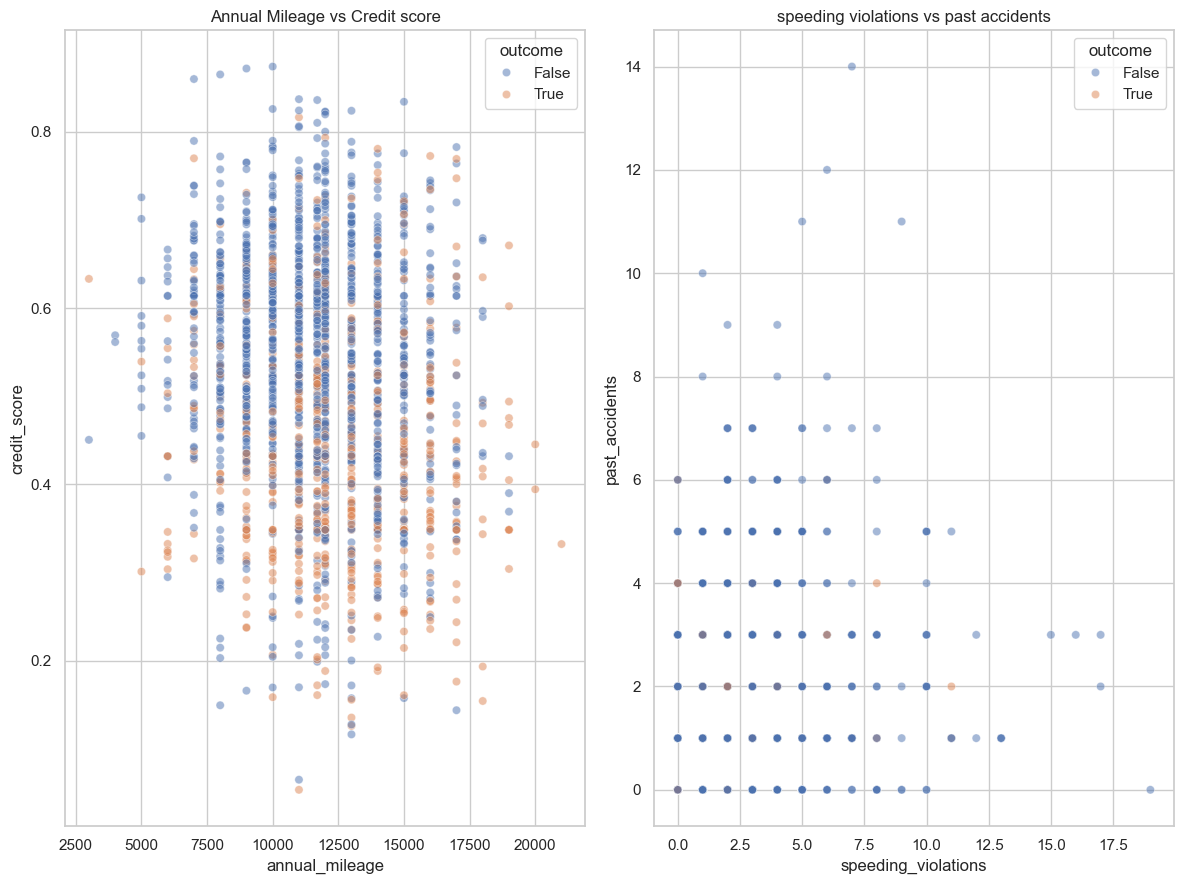

In [15]:
# Scatterplots
sample_df = df.sample(n=min(2000,len(df)),random_state=42)
fig,axes = plt.subplots(1,2,figsize=(12,9))

sns.scatterplot(data=sample_df,x="annual_mileage",y="credit_score",
                hue="outcome",alpha=0.5,ax=axes[0])
axes[0].set_title("Annual Mileage vs Credit score")

sns.scatterplot(data=sample_df,x="speeding_violations",y="past_accidents",
                hue="outcome",alpha=0.5,ax=axes[1])
axes[1].set_title("speeding violations vs past accidents")

plt.tight_layout()
plt.show()

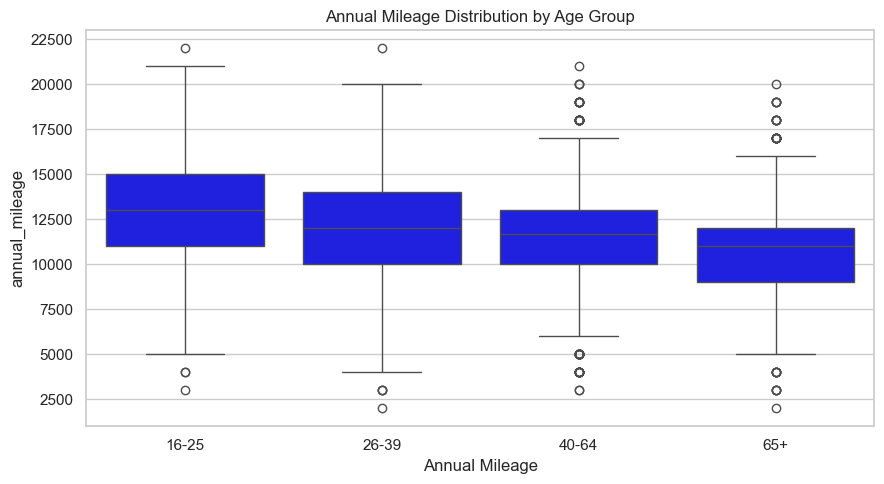

In [16]:
#Mileage across age group
age_order = ["16-25","26-39","40-64","65+"]
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x="age",y="annual_mileage",order=age_order,color="blue")
plt.title("Annual Mileage Distribution by Age Group")
plt.xlabel("Annual Mileage")
plt.tight_layout()
plt.show()

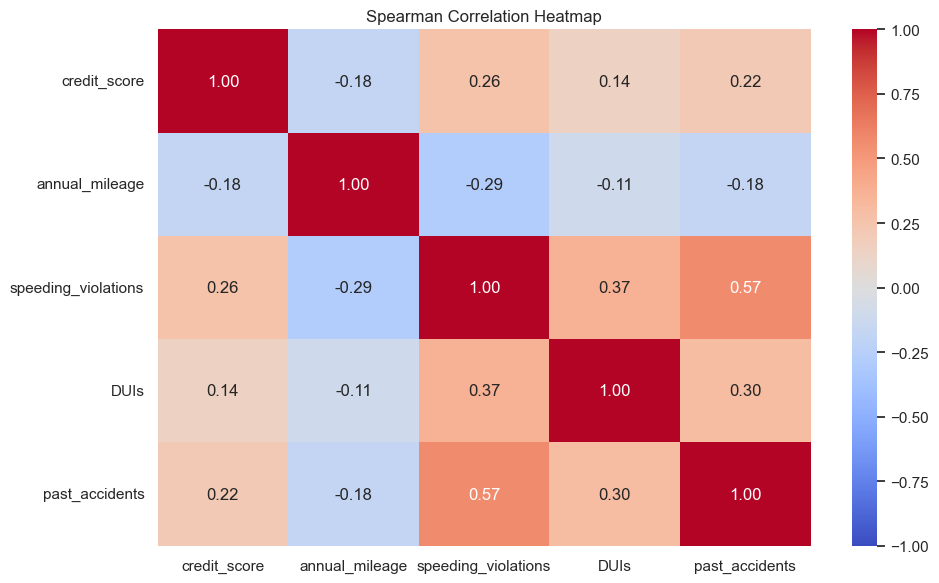

In [17]:
# Multivariate Analysis-correlation
numeric_df = df[numeric_cols]
correlation = numeric_df.corr(method="spearman")

plt.figure(figsize=(10,6))
sns.heatmap(correlation,annot=True,cmap="coolwarm",center=0,fmt=".2f",vmin=-1,vmax=1)
plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
#statistical test 
from scipy.stats import chi2_contingency
contingency_table = pd.crosstab(df["vehicle_type"],
df["outcome"])

chi2,p_value,dof,expected = chi2_contingency(contingency_table)
print("Contingency table")
display(contingency_table)

print(f"Chi-square statistic:{chi2:.3f}")
print(f"Degrees of freedom:{dof}")
print(f"P-valueL{p_value:.5f}")

if p_value < 0.05:
    print("Evidence of an association between vehicle type and outcome")
else:
    print("Insufficient evidence")

Contingency table


outcome,False,True
vehicle_type,,
sedan,6545,2978
sports car,322,155


Chi-square statistic:0.262
Degrees of freedom:1
P-valueL0.60905
Insufficient evidence
